# Disponibilidad batch — fases 2 a 6

Cuaderno evolutivo: inspección, Silver, Gold y comparación/evaluación experimental. Cada sección avanzada tiene arranque independiente; sus ejecuciones conservan entradas fijadas y salidas históricas. Fase 5 utiliza únicamente Gold `20261117T044523230826Z`, sin descargas ni cambios de cortes.

Se predicen conteos reportados por tipo, cuya exactitud física no está confirmada. Elegibilidad no garantiza exactitud. La selección usa validación y se congela antes de evaluar prueba; se mantienen los tres horizontes. No se implementa U2 ni integración final.


In [1]:
from pathlib import Path
import sys, json
candidatos = [Path('/opt/UNIDAD1/Dim-Disponibilidad'), Path.cwd(), *Path.cwd().parents]
RAIZ = next(p for p in candidatos if (p / 'src/lectura.py').is_file())
sys.path.insert(0, str(RAIZ))
from src.lectura import estructura_local, leer_fuente
from src.diagnostico import diagnosticar, intervalos
from pyspark.sql import SparkSession, functions as F
from pyspark import StorageLevel
spark = (SparkSession.builder.appName('U1_Disponibilidad_Inspeccion')
         .master('local[2]').config('spark.driver.memory', '3g')
         .config('spark.sql.shuffle.partitions', '8')
         .config('spark.sql.session.timeZone', 'UTC').getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
assert spark.conf.get('spark.sql.session.timeZone') == 'UTC'
RAW = RAIZ / 'data/raw'
REPORTS = RAIZ / 'reports/inspeccion'
print('Spark:', spark.version, '| Python:', sys.version.split()[0])
print('Raíz:', RAIZ, '| originales:', RAW)


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/17 04:04:06 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark: 4.2.0 | Python: 3.10.22
Raíz: /opt/UNIDAD1/Dim-Disponibilidad | originales: /opt/UNIDAD1/Dim-Disponibilidad/data/raw


## Estructura realmente observada
Se inspeccionan las claves y tipos de **todos** los gzip locales, sin asumir que el primero representa todo el histórico. Las fuentes mantienen esquemas distintos. Los errores de lectura se reportan y bloquean la interpretación hasta revisarlos.

In [2]:
estructura = estructura_local(RAW)
print(json.dumps(estructura, indent=2, ensure_ascii=False))
assert all(not s['errores'] for s in estructura.values()), 'Revisar errores de originales'


{
  "station_information": {
    "archivos": 1,
    "raiz": [
      "data",
      "last_updated",
      "ttl",
      "version"
    ],
    "data": [
      "stations"
    ],
    "campos": {
      "capacity": [
        "int"
      ],
      "is_charging": [
        "bool"
      ],
      "lat": [
        "float"
      ],
      "lon": [
        "float"
      ],
      "name": [
        "str"
      ],
      "region_id": [
        "str"
      ],
      "rental_uris": [
        "dict"
      ],
      "short_name": [
        "str"
      ],
      "station_id": [
        "str"
      ]
    },
    "errores": []
  },
  "station_status": {
    "archivos": 288,
    "raiz": [
      "data",
      "last_updated",
      "ttl",
      "version"
    ],
    "data": [
      "stations"
    ],
    "campos": {
      "is_installed": [
        "int"
      ],
      "is_renting": [
        "int"
      ],
      "is_returning": [
        "int"
      ],
      "last_reported": [
        "int"
      ],
      "num_bikes_availa

In [3]:
fuentes = {}
for fuente in ('station_status', 'station_information', 'vehicle_types'):
    feed, filas = leer_fuente(spark, RAW, fuente)
    fuentes[fuente] = (feed.persist(StorageLevel.MEMORY_AND_DISK), filas.persist(StorageLevel.MEMORY_AND_DISK))
    print('FUENTE:', fuente, '| archivos:', feed.count(), '| registros:', filas.count())
    filas.printSchema()
    filas.show(3, truncate=75)
feed, estados = fuentes['station_status']
_, estaciones = fuentes['station_information']
_, vehiculos = fuentes['vehicle_types']


FUENTE: station_status | archivos: 288 | registros: 725706
root
 |-- archivo_origen: string (nullable = false)
 |-- captura_utc: timestamp (nullable = false)
 |-- last_updated: long (nullable = true)
 |-- last_updated_utc: timestamp (nullable = true)
 |-- ttl: long (nullable = true)
 |-- version: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- num_bikes_available: long (nullable = true)
 |-- num_ebikes_available: long (nullable = true)
 |-- num_bikes_disabled: long (nullable = true)
 |-- num_docks_available: long (nullable = true)
 |-- num_docks_disabled: long (nullable = true)
 |-- is_installed: long (nullable = true)
 |-- is_renting: long (nullable = true)
 |-- is_returning: long (nullable = true)
 |-- last_reported: long (nullable = true)
 |-- num_scooters_available: long (nullable = true)
 |-- num_scooters_unavailable: long (nullable = true)
 |-- vehicle_types_available: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- v

+---------------------------------------------------------------------------+-----------------------+------------+-------------------+---+-------+------------------------------------+-------------------+--------------------+------------------+-------------------+------------------+------------+----------+------------+-------------+----------------------+------------------------+-----------------------+-----------------------+----------------+-------------------+
|                                                             archivo_origen|            captura_utc|last_updated|   last_updated_utc|ttl|version|                          station_id|num_bikes_available|num_ebikes_available|num_bikes_disabled|num_docks_available|num_docks_disabled|is_installed|is_renting|is_returning|last_reported|num_scooters_available|num_scooters_unavailable|vehicle_types_available|     captura_nueva_york|fecha_nueva_york|  last_reported_utc|
+-----------------------------------------------------------------

FUENTE: station_information | archivos: 1 | registros: 2520
root
 |-- archivo_origen: string (nullable = false)
 |-- captura_utc: timestamp (nullable = false)
 |-- last_updated: long (nullable = true)
 |-- last_updated_utc: timestamp (nullable = true)
 |-- ttl: long (nullable = true)
 |-- version: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- name: string (nullable = true)
 |-- short_name: string (nullable = true)
 |-- lon: double (nullable = true)
 |-- lat: double (nullable = true)
 |-- region_id: string (nullable = true)
 |-- capacity: long (nullable = true)
 |-- rental_uris: map (nullable = true)
 |    |-- key: string
 |    |-- value: string (valueContainsNull = true)
 |-- is_charging: boolean (nullable = true)
 |-- captura_nueva_york: timestamp (nullable = false)
 |-- fecha_nueva_york: date (nullable = false)



+---------------------------------------------------------------------------+-----------------------+------------+-------------------+---+-------+------------------------------------+--------------------------+----------+------------------+-----------------+---------+--------+---------------------------------------------------------------------------+-----------+-----------------------+----------------+
|                                                             archivo_origen|            captura_utc|last_updated|   last_updated_utc|ttl|version|                          station_id|                      name|short_name|               lon|              lat|region_id|capacity|                                                                rental_uris|is_charging|     captura_nueva_york|fecha_nueva_york|
+---------------------------------------------------------------------------+-----------------------+------------+-------------------+---+-------+------------------------------------+---

FUENTE: vehicle_types | archivos: 1 | registros: 2
root
 |-- archivo_origen: string (nullable = false)
 |-- captura_utc: timestamp (nullable = false)
 |-- last_updated: long (nullable = true)
 |-- last_updated_utc: timestamp (nullable = true)
 |-- ttl: long (nullable = true)
 |-- version: string (nullable = true)
 |-- vehicle_type_id: string (nullable = true)
 |-- form_factor: string (nullable = true)
 |-- propulsion_type: string (nullable = true)
 |-- max_range_meters: double (nullable = true)
 |-- captura_nueva_york: timestamp (nullable = false)
 |-- fecha_nueva_york: date (nullable = false)

+---------------------------------------------------------------------------+-----------------------+------------+-------------------+---+-------+---------------+-----------+---------------+----------------+-----------------------+----------------+
|                                                             archivo_origen|            captura_utc|last_updated|   last_updated_utc|ttl|version|veh

## Tiempos y trazabilidad
`captura_utc` procede del nombre del archivo (convención observada, sin `captured_at` en JSON). `last_updated` y `last_reported` se mantienen como enteros originales y también se expresan como timestamps UTC. El primero es actualización del feed, el segundo reporte de la estación. `captura_nueva_york` es una representación de hora de pared; la sesión permanece UTC. Se deriva `fecha_nueva_york` para estudiar días de uso.

No se crean filas de estación para arrays vacíos: estos se diagnostican en el DataFrame de feeds.

In [4]:
estados.select('archivo_origen', 'station_id', 'captura_utc', 'captura_nueva_york',
               'fecha_nueva_york', 'last_updated', 'last_updated_utc',
               'last_reported', 'last_reported_utc').show(5, truncate=70)
estados.groupBy('fecha_nueva_york').count().orderBy('fecha_nueva_york').show()


+----------------------------------------------------------------------+------------------------------------+-----------------------+-----------------------+----------------+------------+-------------------+-------------+-------------------+
|                                                        archivo_origen|                          station_id|            captura_utc|     captura_nueva_york|fecha_nueva_york|last_updated|   last_updated_utc|last_reported|  last_reported_utc|
+----------------------------------------------------------------------+------------------------------------+-----------------------+-----------------------+----------------+------------+-------------------+-------------+-------------------+
|file:///opt/UNIDAD1/Dim-Disponibilidad/data/raw/station_status/2026...|66dc292c-0aca-11e7-82f6-3863bb44ef7c|2026-11-10 18:40:01.621|2026-11-10 13:40:01.621|      2026-11-10|  1794335945|2026-11-10 18:39:05|        86400|1970-01-02 00:00:00|
|file:///opt/UNIDAD1/Dim-Disponi

+----------------+------+
|fecha_nueva_york| count|
+----------------+------+
|      2026-11-09|151200|
|      2026-11-10|574506|
+----------------+------+



## Diagnóstico, claves y catálogos
Antes de enriquecer se comprueban unicidad y correspondencia de IDs. La tabla principal permanece sin joins. Solo la comparación exploratoria de capacidad usa un join izquierdo si `station_information` tiene ID único. Este catálogo diario no se considera válido retroactivamente para entrenamiento: una futura integración debe resolver vigencia/as-of sin usar información del futuro.

Convencionales se inspeccionan a través de `vehicle_types_available` y el catálogo `propulsion_type=human`; eléctricas mediante `electric_assist` y `num_ebikes_available`. Se comprueban sumas y la diferencia total−eléctricas; no se presupone su equivalencia.

In [5]:
resumen, cantidades, conflictos = diagnosticar(feed, estados, estaciones, vehiculos)
print(json.dumps(resumen, default=str, ensure_ascii=False, indent=2))
cantidades.select('station_id', 'captura_utc', 'num_bikes_available', 'num_ebikes_available',
                  'vehicle_types_available', 'convencionales_catalogo', 'electricas_catalogo').show(10, truncate=False)
conflictos.where('variantes > 1').orderBy(F.desc('variantes')).show(10, truncate=False)

cantidades.where((F.col('electricas_catalogo') != F.col('num_ebikes_available')) |
                 (F.col('convencionales_catalogo') + F.col('electricas_catalogo') != F.col('num_bikes_available'))).select(
    'station_id', 'captura_utc', 'num_bikes_available', 'num_ebikes_available',
    'convencionales_catalogo', 'electricas_catalogo', 'vehicle_types_available').show(10, truncate=False)
estados.groupBy('station_id').agg(F.count('*').alias('capturas'),
    F.min('captura_utc').alias('primera'), F.max('captura_utc').alias('ultima')).orderBy('capturas').show(5)


{
  "filas": 725706,
  "archivos_status": 288,
  "estaciones": 2520,
  "periodo": {
    "archivo_min_utc": "2026-11-10 00:00:02.493000",
    "archivo_max_utc": "2026-11-10 23:55:01.713000",
    "feed_min_utc": "2026-11-09 23:58:44",
    "feed_max_utc": "2026-11-10 23:54:05",
    "reporte_min_utc": "1970-01-02 00:00:00",
    "reporte_max_utc": "2026-11-10 23:53:49"
  },
  "nulos": {
    "archivo_origen": 0,
    "captura_utc": 0,
    "last_updated": 0,
    "last_updated_utc": 0,
    "ttl": 0,
    "version": 0,
    "station_id": 0,
    "num_bikes_available": 0,
    "num_ebikes_available": 0,
    "num_bikes_disabled": 0,
    "num_docks_available": 0,
    "num_docks_disabled": 0,
    "is_installed": 0,
    "is_renting": 0,
    "is_returning": 0,
    "last_reported": 0,
    "num_scooters_available": 20667,
    "num_scooters_unavailable": 20667,
    "vehicle_types_available": 0,
    "captura_nueva_york": 0,
    "fecha_nueva_york": 0,
    "last_reported_utc": 0
  },
  "feeds_invalidos": {
    

+------------------------------------+-------------+-----+---------+
|station_id                          |last_reported|filas|variantes|
+------------------------------------+-------------+-----+---------+
|bc5235a5-7f10-4a27-806e-9c25fa700959|1794311586   |3    |3        |
|623c9658-5544-4254-847e-738763cf45a3|1794313032   |95   |3        |
|93e2e1a5-49c5-41f8-a6bf-b399b6a5140d|1794337304   |3    |3        |
|c0ce2a38-04f5-4333-8818-2a3faa84f214|1794295628   |4    |3        |
|08bf2fe0-219d-48cd-87c5-6163b3a2eafd|1794277828   |3    |3        |
|2104286315955915532                 |1794334714   |3    |3        |
|08bf2fe0-219d-48cd-87c5-6163b3a2eafd|1794348377   |3    |3        |
|1861681121800951962                 |1794273740   |271  |3        |
|26568d39-db49-4354-a5c1-c81a3c856285|1794351114   |3    |3        |
|66db95e5-0aca-11e7-82f6-3863bb44ef7c|1794327302   |7    |2        |
+------------------------------------+-------------+-----+---------+
only showing top 10 rows
+--------

+--------------------+--------+--------------------+--------------------+
|          station_id|capturas|             primera|              ultima|
+--------------------+--------+--------------------+--------------------+
| 2100948436010992354|     234|2026-11-10 00:00:...|2026-11-10 19:25:...|
|528ed1e0-75aa-45b...|     288|2026-11-10 00:00:...|2026-11-10 23:55:...|
| 1860189327773878824|     288|2026-11-10 00:00:...|2026-11-10 23:55:...|
| 1869743938848725856|     288|2026-11-10 00:00:...|2026-11-10 23:55:...|
| 1817432434869846072|     288|2026-11-10 00:00:...|2026-11-10 23:55:...|
+--------------------+--------+--------------------+--------------------+
only showing top 5 rows


## Frecuencia, huecos y antigüedad
Se muestran intervalos del archivo y **del feed interno**, además de reportes por estación. Para frecuencia del feed se consideran instantes distintos y se cuenta por separado la reutilización de `last_updated`. Los reportes repetidos no son por sí mismos duplicados: se diagnostican conflictos de contenido bajo el mismo reporte.

Un hueco >450 s es un indicador exploratorio alrededor de 5 minutos con tolerancia, no una frecuencia impuesta. También se inspeccionan extremos y cuantiles. Las fechas inválidas o antiguas pueden distorsionar la cadencia de reportes individuales. No se pueden determinar huecos fuera de los límites del histórico disponible.

In [6]:
for campo in ('captura_utc', 'last_updated_utc'):
    diferencias = intervalos(feed, campo)
    print('Intervalos de', campo)
    diferencias.orderBy(F.desc('intervalo_s')).show(10, truncate=False)
    diferencias.select('intervalo_s').summary('min', '25%', '50%', '75%', 'max').show()
estados.select((F.col('last_updated') - F.col('last_reported')).alias('edad_reporte_s')).summary().show()
estados.where(F.col('last_updated') - F.col('last_reported') > 86400).select(
    'station_id', 'captura_utc', 'last_reported', 'last_reported_utc', 'is_installed', 'is_renting').show(10)


Intervalos de captura_utc


+-----------------------+-----------------------+------------------+
|captura_utc            |anterior               |intervalo_s       |
+-----------------------+-----------------------+------------------+
|2026-11-10 03:00:05.877|2026-11-10 02:55:01.588|304.2890000343323 |
|2026-11-10 16:15:04.28 |2026-11-10 16:10:01.54 |302.74000000953674|
|2026-11-10 12:00:03.957|2026-11-10 11:55:01.49 |302.4670000076294 |
|2026-11-10 04:00:03.548|2026-11-10 03:55:01.234|302.3140001296997 |
|2026-11-10 12:55:03.337|2026-11-10 12:50:01.608|301.72899985313416|
|2026-11-10 21:50:03.265|2026-11-10 21:45:01.57 |301.6950001716614 |
|2026-11-10 09:20:03.432|2026-11-10 09:15:01.756|301.67599987983704|
|2026-11-10 01:30:03.09 |2026-11-10 01:25:01.479|301.6109998226166 |
|2026-11-10 21:20:04.822|2026-11-10 21:15:03.271|301.5510001182556 |
|2026-11-10 13:20:03.152|2026-11-10 13:15:01.608|301.5439999103546 |
+-----------------------+-----------------------+------------------+
only showing top 10 rows


+-------+------------------+
|summary|       intervalo_s|
+-------+------------------+
|    min|295.93299984931946|
|    25%|  299.452999830246|
|    50%|300.07100009918213|
|    75%| 300.5149998664856|
|    max| 304.2890000343323|
+-------+------------------+

Intervalos de last_updated_utc


+-------------------+-------------------+-----------+
|last_updated_utc   |anterior           |intervalo_s|
+-------------------+-------------------+-----------+
|2026-11-10 17:29:05|2026-11-10 17:23:44|321.0      |
|2026-11-10 15:03:44|2026-11-10 14:58:29|315.0      |
|2026-11-10 01:33:46|2026-11-10 01:28:44|302.0      |
|2026-11-10 03:08:46|2026-11-10 03:03:44|302.0      |
|2026-11-10 04:18:46|2026-11-10 04:13:44|302.0      |
|2026-11-10 05:43:46|2026-11-10 05:38:44|302.0      |
|2026-11-10 08:33:30|2026-11-10 08:28:28|302.0      |
|2026-11-10 09:28:30|2026-11-10 09:23:28|302.0      |
|2026-11-10 09:53:30|2026-11-10 09:48:28|302.0      |
|2026-11-10 10:38:30|2026-11-10 10:33:28|302.0      |
+-------------------+-------------------+-----------+
only showing top 10 rows


+-------+-----------+
|summary|intervalo_s|
+-------+-----------+
|    min|      284.0|
|    25%|      300.0|
|    50%|      300.0|
|    75%|      300.0|
|    max|      321.0|
+-------+-----------+



+-------+--------------------+
|summary|      edad_reporte_s|
+-------+--------------------+
|  count|              725706|
|   mean|3.2639260899343535E7|
| stddev|2.3976194510025328E8|
|    min|                   6|
|    25%|                  36|
|    50%|                  58|
|    75%|                  91|
|    max|          1794268445|
+-------+--------------------+

+--------------------+--------------------+-------------+-------------------+------------+----------+
|          station_id|         captura_utc|last_reported|  last_reported_utc|is_installed|is_renting|
+--------------------+--------------------+-------------+-------------------+------------+----------+
|66dc292c-0aca-11e...|2026-11-10 18:40:...|        86400|1970-01-02 00:00:00|           0|         0|
|475c44e1-31e3-4c6...|2026-11-10 18:40:...|        86400|1970-01-02 00:00:00|           0|         0|
|ba33c334-e17d-447...|2026-11-10 18:40:...|        86400|1970-01-02 00:00:00|           0|         0|
|06439006-11b6-

## Reglas propuestas (sin aplicar)

- Conservar originales, archivo de origen y los tres relojes; marcar parseos inválidos, campos obligatorios ausentes y tipos desconocidos.
- Mantener todas las observaciones repetidas entre capturas. Revisar por separado duplicados exactos dentro de un archivo, conflictos estación/captura y variantes con igual `last_reported`.
- Etiquetar estados operativos, conteos negativos, sumas incoherentes y antigüedad; no descartar automáticamente por umbrales exploratorios de 15 minutos o 24 horas.
- Validar correspondencia temporal de catálogos, capacidades e IDs antes de enriquecer. Los catálogos diarios pueden ser posteriores a parte de los estados del mismo día.
- Para futuros objetivos de 5/10/15 minutos usar tiempos UTC observados, tolerancias explícitas y banderas de huecos; no rellenar ni interpolar aún.
- Evaluar la representatividad de más días antes de elegir horizonte o regla definitiva. Un día no permite validar ciclos semanales ni efectos del cambio horario.

Las conclusiones cuantitativas verificadas aparecen en el resumen de ejecución y en `reports/inspeccion/hallazgos.md`.

# Fase 3 — investigación y Silver
Las reglas se evalúan después de inspeccionar cantidades, conflictos, antigüedad y cobertura. Se preservan todas las cantidades raw y todas las observaciones entre momentos distintos. Los aceptados tienen al menos un objetivo observacional elegible; los demás se conservan íntegros en excluidos con motivos. Inactividad no significa invalidez. No se entrena ni se definen aún etiquetas futuras de 5/10/15 minutos.

In [7]:
from src.calidad import investigar, perfilar_discrepancias, aplicar_reglas, guardar_y_verificar
from datetime import datetime, timezone
REPORTS_CALIDAD = RAIZ / 'reports/calidad'
REPORTS_CALIDAD.mkdir(parents=True, exist_ok=True)
por_captura, por_reporte, edades = investigar(estados)
discrepancias = cantidades.withColumn('delta_total_tipos', F.col('num_bikes_available') -
    F.aggregate('vehicle_types_available', F.lit(0).cast('long'), lambda a, v: a + v['count']))
deltas = discrepancias.where('delta_total_tipos != 0').groupBy('delta_total_tipos').count()
deltas.orderBy(F.desc('count')).show(30)
discrepancias.where('delta_total_tipos != 0').select(
    'archivo_origen', 'station_id', 'captura_utc', 'last_reported', 'num_bikes_available',
    'num_ebikes_available', 'num_bikes_disabled', 'num_scooters_available',
    'vehicle_types_available', 'delta_total_tipos').show(10, truncate=False)
vehiculos.select('vehicle_type_id', 'propulsion_type', 'archivo_origen', 'captura_utc').show(truncate=False)
scooters = estados.agg(*[F.sum(F.when(F.col(c) > 0, 1).otherwise(0)).alias(c + '_positivos') for c in ('num_scooters_available', 'num_scooters_unavailable')]).first().asDict()
print('Campos scooters: positivos observados', scooters)
relacion = discrepancias.where('delta_total_tipos != 0').agg(
    F.count('*').alias('discrepancias'),
    F.sum(F.when(F.col('delta_total_tipos') == F.col('num_scooters_available'), 1).otherwise(0)).alias('coincide_scooters'),
    F.sum(F.when(F.col('delta_total_tipos') == F.col('num_bikes_disabled'), 1).otherwise(0)).alias('coincide_disabled')).first().asDict()
conflictos58 = por_reporte.where('variantes > 1')
conflictos58.orderBy(F.desc('filas')).show(10, truncate=False)
cambios_campos = conflictos58.agg(*[F.sum(F.when(F.col(c) > 1, 1).otherwise(0)).alias(c)
    for c in conflictos58.columns if c.startswith('variantes_')]).first().asDict()
edades.orderBy('is_installed', 'is_renting', 'is_returning').show(truncate=False)
parcial = estados.where(F.col('station_id') == '2100948436010992354')
parcial.groupBy('is_installed', 'is_renting', 'is_returning').agg(
    F.count('*').alias('filas'), F.min('captura_utc').alias('primera'), F.max('captura_utc').alias('ultima')).show(truncate=False)
parcial.orderBy(F.desc('captura_utc')).select('captura_utc', 'last_reported', 'num_bikes_available',
    'num_ebikes_available', 'vehicle_types_available', 'is_installed', 'is_renting', 'is_returning').show(5, truncate=False)
ausencias_parcial = feed.select('captura_utc').join(parcial.select('captura_utc'), 'captura_utc', 'left_anti')
# Vista diagnóstica de ausencias, no se añaden filas al histórico.
investigacion = {
    'discrepancias': relacion, 'campos_scooters_sin_evidencia_operativa': scooters,
    'deltas': [r.asDict() for r in deltas.orderBy('delta_total_tipos').collect()],
    'conflictos_entre_capturas': conflictos58.where('capturas > 1').count(),
    'conflictos_dentro_captura': por_captura.where('variantes > 1').count(),
    'cambios_por_campo': cambios_campos,
    'edades_por_estados': [r.asDict() for r in edades.collect()],
    'estacion_parcial': {'observaciones': parcial.count(), 'ausencias': ausencias_parcial.count(),
        'estados': [r.asDict() for r in parcial.groupBy('is_installed', 'is_renting', 'is_returning').count().collect()],
        'limites_ausencia': ausencias_parcial.agg(F.min('captura_utc').alias('primera'), F.max('captura_utc').alias('ultima')).first().asDict()}}
print(json.dumps(investigacion, default=str, ensure_ascii=False, indent=2))

perfil = perfilar_discrepancias(cantidades)
investigacion['perfil_discrepancias'] = perfil
print(json.dumps(perfil, default=str, ensure_ascii=False, indent=2))


+-----------------+-----+
|delta_total_tipos|count|
+-----------------+-----+
|                1|13371|
|               -1|11846|
|                2|  849|
|               -2|  766|
|               -3|   83|
|                3|   79|
|                4|   18|
|               -4|   14|
|                5|    6|
|               -6|    5|
|               -8|    4|
|               10|    4|
|                9|    3|
|               -5|    3|
|               -7|    2|
|                6|    2|
|              -11|    1|
|               11|    1|
|              -12|    1|
|               33|    1|
|              -14|    1|
|              -16|    1|
|               12|    1|
|                8|    1|
|               16|    1|
|               28|    1|
|               58|    1|
|              -13|    1|
+-----------------+-----+

+-----------------------------------------------------------------------------------------------------------------------------------------------+----------------------

+---------------+---------------+----------------------------------------------------------------------------------------------------------------------------------------------+-----------------------+
|vehicle_type_id|propulsion_type|archivo_origen                                                                                                                                |captura_utc            |
+---------------+---------------+----------------------------------------------------------------------------------------------------------------------------------------------+-----------------------+
|1              |human          |file:///opt/UNIDAD1/Dim-Disponibilidad/data/raw/vehicle_types/2026-11-10/2026-11-10T04-02-00-922Z-baf1ba61-6829-4349-be83-8750e69408b3.json.gz|2026-11-10 04:02:00.922|
|2              |electric_assist|file:///opt/UNIDAD1/Dim-Disponibilidad/data/raw/vehicle_types/2026-11-10/2026-11-10T04-02-00-922Z-baf1ba61-6829-4349-be83-8750e69408b3.json.gz|2026-11-10 04:02:00.

Campos scooters: positivos observados {'num_scooters_available_positivos': 0, 'num_scooters_unavailable_positivos': 0}


+------------------------------------+-------------+-----+--------+---------+-----------------------------+------------------------------+----------------------------+---------------------------------+----------------------+--------------------+----------------------+
|station_id                          |last_reported|filas|capturas|variantes|variantes_num_bikes_available|variantes_num_ebikes_available|variantes_num_bikes_disabled|variantes_vehicle_types_available|variantes_is_installed|variantes_is_renting|variantes_is_returning|
+------------------------------------+-------------+-----+--------+---------+-----------------------------+------------------------------+----------------------------+---------------------------------+----------------------+--------------------+----------------------+
|1861681121800951962                 |1794273740   |271  |271     |3        |2                            |2                             |2                           |2                         

+------------+----------+------------+------+------------------------+----------+----------+------------+
|is_installed|is_renting|is_returning|filas |p50_p95_edad_s          |mayor_450s|mayor_900s|mayor_86400s|
+------------+----------+------------+------+------------------------+----------+----------+------------+
|0           |0         |0           |15006 |[1794219211, 1794263645]|14866     |14862     |14794       |
|1           |0         |0           |2907  |[17492, 2263784]        |1954      |1903      |453         |
|1           |1         |1           |707793|[57, 130]               |31        |2         |0           |
+------------+----------+------------+------+------------------------+----------+----------+------------+



+------------+----------+------------+-----+-----------------------+-----------------------+
|is_installed|is_renting|is_returning|filas|primera                |ultima                 |
+------------+----------+------------+-----+-----------------------+-----------------------+
|1           |1         |1           |163  |2026-11-10 00:00:02.493|2026-11-10 13:30:02.215|
|0           |0         |0           |71   |2026-11-10 13:35:02.695|2026-11-10 19:25:01.66 |
+------------+----------+------------+-----+-----------------------+-----------------------+



+-----------------------+-------------+-------------------+--------------------+-----------------------+------------+----------+------------+
|captura_utc            |last_reported|num_bikes_available|num_ebikes_available|vehicle_types_available|is_installed|is_renting|is_returning|
+-----------------------+-------------+-------------------+--------------------+-----------------------+------------+----------+------------+
|2026-11-10 19:25:01.66 |86400        |0                  |0                   |[{1, 0}, {2, 0}]       |0           |0         |0           |
|2026-11-10 19:20:02.036|86400        |0                  |0                   |[{1, 0}, {2, 0}]       |0           |0         |0           |
|2026-11-10 19:15:02.39 |86400        |0                  |0                   |[{1, 0}, {2, 0}]       |0           |0         |0           |
|2026-11-10 19:10:01.972|86400        |0                  |0                   |[{1, 0}, {2, 0}]       |0           |0         |0           |
|2026-

{
  "discrepancias": {
    "discrepancias": 27067,
    "coincide_scooters": 0,
    "coincide_disabled": 2425
  },
  "campos_scooters_sin_evidencia_operativa": {
    "num_scooters_available_positivos": 0,
    "num_scooters_unavailable_positivos": 0
  },
  "deltas": [
    {
      "delta_total_tipos": -16,
      "count": 1
    },
    {
      "delta_total_tipos": -14,
      "count": 1
    },
    {
      "delta_total_tipos": -13,
      "count": 1
    },
    {
      "delta_total_tipos": -12,
      "count": 1
    },
    {
      "delta_total_tipos": -11,
      "count": 1
    },
    {
      "delta_total_tipos": -8,
      "count": 4
    },
    {
      "delta_total_tipos": -7,
      "count": 2
    },
    {
      "delta_total_tipos": -6,
      "count": 5
    },
    {
      "delta_total_tipos": -5,
      "count": 3
    },
    {
      "delta_total_tipos": -4,
      "count": 14
    },
    {
      "delta_total_tipos": -3,
      "count": 83
    },
    {
      "delta_total_tipos": -2,
      "count": 766

{
  "electricas": {
    "escalar_ausente": 0,
    "escalar_cero": 159132,
    "tipo2_ausente": 0,
    "tipo2_cero": 159326,
    "ambas_presentes": 725706,
    "coinciden": 704786,
    "difieren": 20920,
    "escalar_mayor": 11282,
    "escalar_menor": 9638
  },
  "por_hora_local": [
    {
      "hora_nueva_york": 0,
      "observaciones": 30240,
      "discrepancias": 492,
      "positivas": 273,
      "negativas": 219,
      "porcentaje": 1.627
    },
    {
      "hora_nueva_york": 1,
      "observaciones": 30240,
      "discrepancias": 195,
      "positivas": 134,
      "negativas": 61,
      "porcentaje": 0.6448
    },
    {
      "hora_nueva_york": 2,
      "observaciones": 30240,
      "discrepancias": 170,
      "positivas": 112,
      "negativas": 58,
      "porcentaje": 0.5622
    },
    {
      "hora_nueva_york": 3,
      "observaciones": 30240,
      "discrepancias": 162,
      "positivas": 121,
      "negativas": 41,
      "porcentaje": 0.5357
    },
    {
      "hora_nueva_

## Política Silver v2: cantidades reportadas por tipo GBFS

La [página oficial de Citi Bike](https://citibikenyc.com/system-data) remite a GBFS. [GBFS 2.3](https://github.com/MobilityData/gbfs/blob/v2.3/gbfs.md#station_statusjson) define total de vehículos funcionales, conteo por tipo y una suma recomendada, no una igualdad obligatoria. La disponibilidad depende de `is_renting`. La extensión `num_ebikes_available` no está definida allí; no se localizó documentación adicional de Citi Bike que explique sus diferencias.

Se usan los conteos explícitos del array para `human` y `electric_assist`, sin forzar sumas ni reconstruir convencionales mediante resta. Son objetivos observacionales de lo que declara el feed, no verdad física confirmada. La discrepancia con el total o la extensión eléctrica se marca y NO bloquea automáticamente ninguno de los dos objetivos. Cada objetivo requiere su tipo identificado de manera unívoca, presente, no negativo. Si un tipo falta, es ambiguo o su conteo no es válido, solo ese objetivo queda pendiente. No se reemplaza ausencia por cero.

Se exige identidad/trazabilidad y estados operativos válidos, `is_installed=1` e `is_renting=1`. `is_returning=0` se indica, pero por sí solo no impide alquilar. Antigüedad máxima provisional: 450 s, superior al P95 activo de 130 s y equivalente a 1,5 cadencias observadas. Se aplica a reporte frente a feed y a feed frente a archivo. Es una tolerancia operacional para este histórico, no una declaración de cumplimiento del límite de frescura de GBFS ni una elección del horizonte. `last_reported=86400` se marca como valor anómalo observado, no como sentinel documentado por el proveedor.

Los cambios entre capturas con igual `last_reported` se conservan. Conflictos dentro de una misma captura se excluyen sin elegir versión. No se eliminan duplicados exactos automáticamente. No se usa capacidad del catálogo diario para invalidar, pues su vigencia/semántica están pendientes. El impacto de estas reglas aparece en los conteos siguientes.


In [8]:
calificados = aplicar_reglas(estados, vehiculos, max_edad_s=450).persist(StorageLevel.MEMORY_AND_DISK)
assert calificados.count() == estados.count()
calificados.groupBy('tipo_registro', 'aceptado_silver', 'elegible_convencionales', 'elegible_electricas').count().show(truncate=False)
calificados.where('elegible_convencionales != elegible_electricas').select(
    'station_id', 'captura_utc', 'num_bikes_available', 'num_ebikes_available',
    'convencionales_tipo', 'electricas_tipo', 'objetivo_convencionales', 'objetivo_electricas',
    'motivos_no_elegible_convencionales', 'motivos_no_elegible_electricas').show(10, truncate=False)
calificados.where('NOT aceptado_silver').select('station_id', 'captura_utc', 'tipo_registro',
    'edad_reporte_s', 'is_installed', 'is_renting', 'is_returning', 'motivos_exclusion').show(10, truncate=False)


+-------------+---------------+-----------------------+-------------------+------+
|tipo_registro|aceptado_silver|elegible_convencionales|elegible_electricas|count |
+-------------+---------------+-----------------------+-------------------+------+
|activo       |true           |true                   |true               |707762|
|inactivo     |false          |false                  |false              |17913 |
|activo       |false          |false                  |false              |31    |
+-------------+---------------+-----------------------+-------------------+------+



+----------+-----------+-------------------+--------------------+-------------------+---------------+-----------------------+-------------------+----------------------------------+------------------------------+
|station_id|captura_utc|num_bikes_available|num_ebikes_available|convencionales_tipo|electricas_tipo|objetivo_convencionales|objetivo_electricas|motivos_no_elegible_convencionales|motivos_no_elegible_electricas|
+----------+-----------+-------------------+--------------------+-------------------+---------------+-----------------------+-------------------+----------------------------------+------------------------------+
+----------+-----------+-------------------+--------------------+-------------------+---------------+-----------------------+-------------------+----------------------------------+------------------------------+

+-------------------+-----------------------+-------------+--------------+------------+----------+------------+--------------------------------------+


## Escritura y lectura de vuelta
Cada ejecución crea un directorio nuevo bajo `data/silver/`; raw y ejecuciones anteriores permanecen intactos. Los dos conjuntos son disjuntos y su unión conserva la multiplicidad de entrada. Los motivos solapados se cuentan como incidencias, no se suman como registros excluidos. Se verifican nombres y tipos del esquema (Parquet relaja nullability), conteos y equivalencia mediante `exceptAll` en ambas direcciones.

In [9]:
ejecucion = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
DESTINO_SILVER = RAIZ / 'data/silver' / ejecucion
silver, excluidos, reconciliacion = guardar_y_verificar(calificados, DESTINO_SILVER)
silver.printSchema()
print('Reconciliación:', reconciliacion, '| destino:', DESTINO_SILVER)
silver.groupBy('fecha_captura_utc').count().show()
excluidos.groupBy('fecha_captura_utc', 'tipo_registro').count().show()
incidencias = excluidos.select(F.explode('motivos_exclusion').alias('motivo')).groupBy('motivo').count()
incidencias.orderBy(F.desc('count')).show(truncate=False)
combinaciones = excluidos.groupBy('motivos_exclusion').count()
assert sum(r['count'] for r in combinaciones.collect()) == reconciliacion['excluidos']


root
 |-- station_id: string (nullable = true)
 |-- last_reported: long (nullable = true)
 |-- captura_utc: timestamp (nullable = true)
 |-- archivo_origen: string (nullable = true)
 |-- last_updated: long (nullable = true)
 |-- last_updated_utc: timestamp (nullable = true)
 |-- ttl: long (nullable = true)
 |-- version: string (nullable = true)
 |-- num_bikes_available: long (nullable = true)
 |-- num_ebikes_available: long (nullable = true)
 |-- num_bikes_disabled: long (nullable = true)
 |-- num_docks_available: long (nullable = true)
 |-- num_docks_disabled: long (nullable = true)
 |-- is_installed: long (nullable = true)
 |-- is_renting: long (nullable = true)
 |-- is_returning: long (nullable = true)
 |-- num_scooters_available: long (nullable = true)
 |-- num_scooters_unavailable: long (nullable = true)
 |-- vehicle_types_available: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- vehicle_type_id: string (nullable = true)
 |    |    |-- count

+-----------------+------+
|fecha_captura_utc| count|
+-----------------+------+
|       2026-11-10|707762|
+-----------------+------+



+-----------------+-------------+-----+
|fecha_captura_utc|tipo_registro|count|
+-----------------+-------------+-----+
|       2026-11-10|     inactivo|17913|
|       2026-11-10|       activo|   31|
+-----------------+-------------+-----+



+----------------------------+-----+
|motivo                      |count|
+----------------------------+-----+
|estacion_no_alquila         |17913|
|reporte_antiguo             |16851|
|tiempo_reporte_no_utilizable|13199|
+----------------------------+-----+



In [10]:
fecha_prueba = str(silver.select(F.min('fecha_captura_utc')).first()[0])
consulta_fecha = silver.where(F.col('fecha_captura_utc') == F.lit(fecha_prueba).cast('date'))
consulta_fecha.explain(mode='formatted')
plan = consulta_fecha._jdf.queryExecution().executedPlan().toString()
assert 'PartitionFilters:' in plan and 'fecha_captura_utc' in plan
assert consulta_fecha.count() == calificados.where(
    F.col('aceptado_silver') & (F.col('fecha_captura_utc') == F.lit(fecha_prueba).cast('date'))).count()
resultado_calidad = {
    'ejecucion_utc': ejecucion, 'version': 'silver-v2-tipos-gbfs', 'destino': str(DESTINO_SILVER),
    'investigacion': investigacion, 'reconciliacion': reconciliacion,
    'elegibilidad': [r.asDict() for r in calificados.groupBy('tipo_registro', 'aceptado_silver',
        'elegible_convencionales', 'elegible_electricas').count().collect()],
    'incidencias_no_aditivas': [r.asDict() for r in incidencias.collect()],
    'combinaciones_disjuntas_exclusion': [r.asDict() for r in combinaciones.collect()],
    'partition_filters_verificados': True,
    'impacto_discrepancias': [r.asDict() for r in calificados.where('q_discrepancia_total').groupBy(
        'aceptado_silver','elegible_convencionales','elegible_electricas').count().collect()]}
(REPORTS_CALIDAD / 'resultado.json').write_text(json.dumps(resultado_calidad, default=str,
    ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
(REPORTS_CALIDAD / 'plan_fecha.txt').write_text(plan, encoding='utf-8')
print(json.dumps(resultado_calidad, default=str, ensure_ascii=False, indent=2))
calificados.unpersist()


== Physical Plan ==
* ColumnarToRow (2)
+- Scan parquet  (1)


(1) Scan parquet 
Output [56]: [station_id#54058, last_reported#54059L, captura_utc#54060, archivo_origen#54061, last_updated#54062L, last_updated_utc#54063, ttl#54064L, version#54065, num_bikes_available#54066L, num_ebikes_available#54067L, num_bikes_disabled#54068L, num_docks_available#54069L, num_docks_disabled#54070L, is_installed#54071L, is_renting#54072L, is_returning#54073L, num_scooters_available#54074L, num_scooters_unavailable#54075L, vehicle_types_available#54076, captura_nueva_york#54077, fecha_nueva_york#54078, last_reported_utc#54079, filas_misma_captura#54080L, variantes_misma_captura#54081L, variantes_mismo_reporte#54082L, convencionales_tipo#54083L, electricas_tipo#54084L, regla_version#54085, umbral_frescura_s#54086, edad_reporte_s#54087L, edad_feed_s#54088, q_catalogo_ambiguo#54089, q_tipos_desconocidos#54090, q_array_tipos_invalido#54091, q_discrepancia_total#54092, q_discrepancia_electricas#54093, q_dis

{
  "ejecucion_utc": "20261117T040700694357Z",
  "version": "silver-v2-tipos-gbfs",
  "destino": "/opt/UNIDAD1/Dim-Disponibilidad/data/silver/20261117T040700694357Z",
  "investigacion": {
    "discrepancias": {
      "discrepancias": 27067,
      "coincide_scooters": 0,
      "coincide_disabled": 2425
    },
    "campos_scooters_sin_evidencia_operativa": {
      "num_scooters_available_positivos": 0,
      "num_scooters_unavailable_positivos": 0
    },
    "deltas": [
      {
        "delta_total_tipos": -16,
        "count": 1
      },
      {
        "delta_total_tipos": -14,
        "count": 1
      },
      {
        "delta_total_tipos": -13,
        "count": 1
      },
      {
        "delta_total_tipos": -12,
        "count": 1
      },
      {
        "delta_total_tipos": -11,
        "count": 1
      },
      {
        "delta_total_tipos": -8,
        "count": 4
      },
      {
        "delta_total_tipos": -7,
        "count": 2
      },
      {
        "delta_total_tipos": -6

DataFrame[station_id: string, last_reported: bigint, captura_utc: timestamp, archivo_origen: string, last_updated: bigint, last_updated_utc: timestamp, ttl: bigint, version: string, num_bikes_available: bigint, num_ebikes_available: bigint, num_bikes_disabled: bigint, num_docks_available: bigint, num_docks_disabled: bigint, is_installed: bigint, is_renting: bigint, is_returning: bigint, num_scooters_available: bigint, num_scooters_unavailable: bigint, vehicle_types_available: array<struct<vehicle_type_id:string,count:bigint>>, captura_nueva_york: timestamp, fecha_nueva_york: date, last_reported_utc: timestamp, filas_misma_captura: bigint, variantes_misma_captura: bigint, variantes_mismo_reporte: bigint, convencionales_tipo: bigint, electricas_tipo: bigint, regla_version: string, umbral_frescura_s: int, fecha_captura_utc: date, edad_reporte_s: bigint, edad_feed_s: double, q_catalogo_ambiguo: boolean, q_tipos_desconocidos: boolean, q_array_tipos_invalido: boolean, q_discrepancia_total: b

In [11]:
REPORTS.mkdir(parents=True, exist_ok=True)
(REPORTS / 'diagnostico.json').write_text(json.dumps(
    {'estructura': estructura, 'diagnostico': resumen, 'spark': spark.version},
    ensure_ascii=False, default=str, indent=2) + '\n', encoding='utf-8')
print('Diagnóstico local:', REPORTS / 'diagnostico.json')
for feed_df, rows_df in fuentes.values():
    feed_df.unpersist()
    rows_df.unpersist()
# Liberar esta sesión; no afecta otros contenedores.
spark.stop()


Diagnóstico local: /opt/UNIDAD1/Dim-Disponibilidad/reports/inspeccion/diagnostico.json


# Fase 4 — Gold temporal de conteos reportados

Esta sección es independiente y solo usa los 290 archivos locales, representados por **una ejecución Silver fijada** en `reports/preparacion/entradas.json`. El inventario remoto se conserva para después y no se descarga nada al ejecutar este notebook.

Los objetivos son conteos reportados por tipo. Elegibilidad no es garantía de exactitud física. `vehicle_types_available` se elige por ofrecer una definición explícita y uniforme por tipo; la documentación del formato no demuestra que sea físicamente más correcto que `num_ebikes_available`. No se fuerza igualdad ni se oculta la incertidumbre. En fase 5 se evaluarán las mismas predicciones sobre todos los elegibles, sin discrepancias y con discrepancias (inicial y objetivo); los casos desconocidos se reportarán aparte.

Un día UTC permite una separación cronológica técnica, pero no una validación independiente por días, patrones semanales ni estacionalidad.

In [1]:
from pathlib import Path
import sys, json, hashlib
from datetime import datetime, timezone
RAIZ = Path('/opt/UNIDAD1/Dim-Disponibilidad')
assert RAIZ.is_dir(), 'Ejecutar en el Docker PySpark existente'
sys.path.insert(0, str(RAIZ))
from pyspark.sql import SparkSession, functions as F
from pyspark import StorageLevel
from src.preparacion import validar_entrada, construir_variables, construir_gold, verificar_gold, explorar, grafico_svg
from IPython.display import SVG, display
spark = (SparkSession.builder.appName('U1_Disponibilidad_Gold').master('local[2]')
    .config('spark.driver.memory','3g').config('spark.sql.shuffle.partitions','8')
    .config('spark.ui.showConsoleProgress','false').config('spark.sql.session.timeZone','UTC').getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
REPORTES = RAIZ / 'reports/preparacion'
config = json.loads((REPORTES/'entradas.json').read_text())
for item in config['fuentes_raw'] + config['archivos_silver']:
    assert hashlib.sha256(Path(item['ruta']).read_bytes()).hexdigest() == item['sha256'], item['ruta']
assert config['silver_version'] == 'silver-v2-tipos-gbfs'
ORIGEN = Path(config['silver_ruta'])
aceptados_silver = spark.read.parquet(str(ORIGEN/'aceptados'))
excluidos_silver = spark.read.parquet(str(ORIGEN/'excluidos'))
silver_fijado = aceptados_silver.unionByName(excluidos_silver).persist(StorageLevel.MEMORY_AND_DISK)
assert silver_fijado.count() == config['silver_conteos']['entrada']
assert silver_fijado.select('regla_version').distinct().first()[0] == config['silver_version']
validar_entrada(silver_fijado)
print('Silver único:', ORIGEN, '| filas:', silver_fijado.count(), '| Spark:', spark.version)


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/17 04:40:48 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Silver único: /opt/UNIDAD1/Dim-Disponibilidad/data/silver/20261117T040700694357Z | filas: 725706 | Spark: 4.2.0


## Cobertura, huecos y EDA
Se lee también el conjunto excluido de **esa misma ejecución Silver** para no ocultar inactividad o huecos. No se mezclan ejecuciones. Los gráficos solo usan agregados horarios pequeños; no se convierte el histórico a pandas. Los períodos de cero son secuencias de snapshots elegibles: su duración es el tiempo observado entre primero y último, no prueba de continuidad física entre capturas.

{
  "cobertura_fecha": [
    {
      "fecha_captura_utc": "2026-11-10",
      "observaciones": 725706,
      "archivos": 288,
      "estaciones": 2520,
      "aceptados": 707762,
      "discrepancia_total": 27067,
      "primera_utc": "2026-11-10 00:00:02.493000",
      "ultima_utc": "2026-11-10 23:55:01.713000"
    }
  ],
  "cobertura_estaciones": {
    "estaciones": 2520,
    "min_capturas": 234,
    "max_capturas": 288,
    "min_elegibles": 0,
    "p50_p95_elegibles": [
      288,
      288
    ]
  },
  "estaciones_menor_cobertura": [
    {
      "station_id": "2100948436010992354",
      "capturas": 234,
      "elegibles": 163,
      "primera_utc": "2026-11-10 00:00:02.493000",
      "ultima_utc": "2026-11-10 19:25:01.660000"
    },
    {
      "station_id": "00284700-9d22-42ce-8485-113fed9879c1",
      "capturas": 288,
      "elegibles": 288,
      "primera_utc": "2026-11-10 00:00:02.493000",
      "ultima_utc": "2026-11-10 23:55:01.713000"
    },
    {
      "station_id": "002e6e

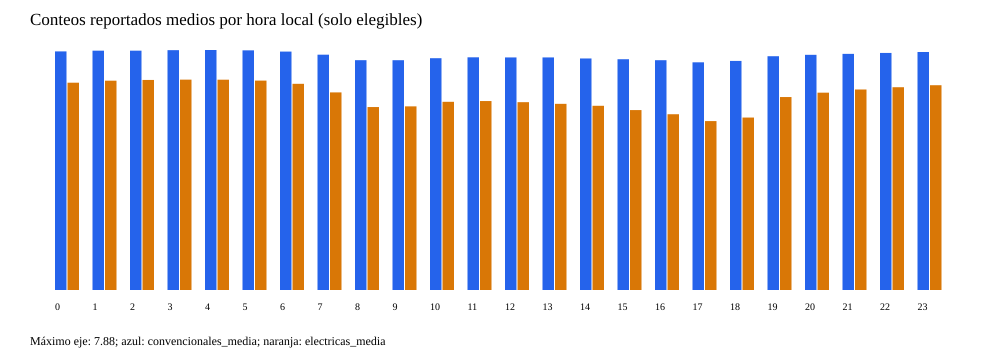

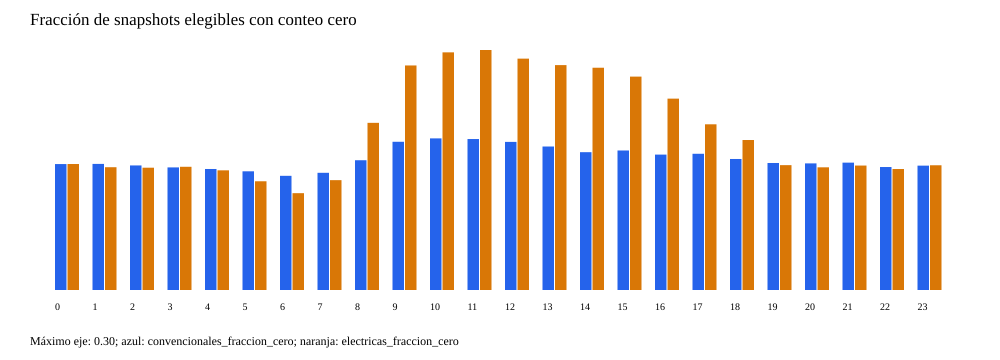

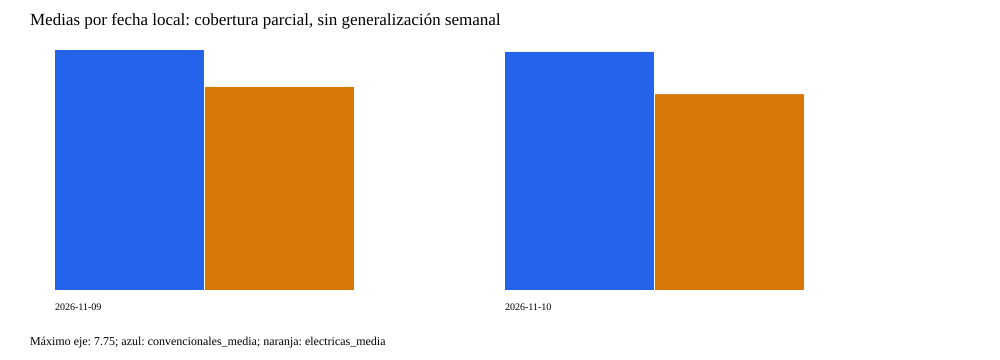

In [2]:
variables, features_numericas = construir_variables(silver_fijado,
    hueco_s=config['hueco_max_s'], tolerancia_s=config['tolerancia_s'])
variables = variables.persist(StorageLevel.MEMORY_AND_DISK)
variables.count()
eda = explorar(silver_fijado, variables)
print(json.dumps(eda, default=str, ensure_ascii=False, indent=2))
grafico_svg(REPORTES/'disponibilidad_horaria.svg',eda['por_hora'],'hora_local',
    ['convencionales_media','electricas_media'],'Conteos reportados medios por hora local (solo elegibles)')
grafico_svg(REPORTES/'ceros_horarios.svg',eda['por_hora'],'hora_local',
    ['convencionales_fraccion_cero','electricas_fraccion_cero'],'Fracción de snapshots elegibles con conteo cero')
grafico_svg(REPORTES/'dia_local.svg',eda['por_dia_local'],'fecha_nueva_york',
    ['convencionales_media','electricas_media'],'Medias por fecha local: cobertura parcial, sin generalización semanal')
for name in ('disponibilidad_horaria.svg','ceros_horarios.svg','dia_local.svg'):
    display(SVG(filename=str(REPORTES/name)))


## Variables, objetivos y cortes cronológicos

Se usan timestamps de captura como tiempo de emisión/disponibilidad de la información. Los relojes del feed y estación permanecen como trazabilidad. La mediana real de captura es ~300 s; su jitter observado es de pocos segundos. Se fija **±30 s**, 10% de la cadencia y menor que media separación entre snapshots. No se emparejan filas fuera de esa banda.

Los rezagos eligen la última observación dentro de la banda alrededor de 5/10/15 minutos antes, siempre anterior a la emisión. Guardan su timestamp real. Las ventanas de 15 minutos excluyen el presente. Un salto >450 s o una observación no elegible inicia un tramo nuevo por tipo: no se atraviesan huecos ni episodios de inactividad. Historial insuficiente produce variables nulas y contadores de muestras; no cantidades imputadas en cero.

Para cada horizonte se elige la captura más cercana al instante esperado y luego se evalúa su calidad. No se salta una captura inválida buscando una etiqueta conveniente. Se guardan timestamp objetivo, horizonte efectivo, motivos y flags iniciales/futuros. Los conflictos entre reportes calculados con todo el día son retrospectivos: auditoría, **prohibidos como predictores**, al igual que todo `f_*`, `y_*`, estrato y motivos. La lista de variables es explícita.

Cortes UTC comunes: entrenamiento [inicio,16:00), validación [16:00,20:00), prueba [20:00,24:00). Los objetivos que toquen o crucen el siguiente corte se purgan por horizonte. Estos segmentos cubren horas locales distintas: no bastan para afirmar generalización a otro día. No se unen metadatos ni se aprende ningún parámetro.

In [3]:
gold_completo = construir_gold(variables,
    config['corte_validacion_utc'],config['corte_prueba_utc'],config['fin_exclusivo_utc'],
    horizontes=tuple(config['horizontes_min']),tolerancia_s=config['tolerancia_s']).persist(StorageLevel.DISK_ONLY)
assert gold_completo.count() == silver_fijado.count() * len(config['horizontes_min'])
assert verificar_gold(gold_completo,features_numericas,config['tolerancia_s'])
print('Variables numéricas permitidas:',features_numericas)
print('Variable categórica disponible:', ['station_id'])
gold_completo.groupBy('particion_temporal','horizonte_min','aceptado_gold').count().orderBy(
    'particion_temporal','horizonte_min','aceptado_gold').show(30, truncate=False)


Variables numéricas permitidas: ['convencionales_actual', 'convencionales_lag5', 'convencionales_cambio5', 'convencionales_lag10', 'convencionales_cambio10', 'convencionales_lag15', 'convencionales_cambio15', 'convencionales_media15', 'convencionales_min15', 'convencionales_max15', 'convencionales_std15', 'convencionales_n15', 'electricas_actual', 'electricas_lag5', 'electricas_cambio5', 'electricas_lag10', 'electricas_cambio10', 'electricas_lag15', 'electricas_cambio15', 'electricas_media15', 'electricas_min15', 'electricas_max15', 'electricas_std15', 'electricas_n15', 'hora_local', 'minuto_local', 'dia_semana_iso', 'fin_semana', 'hora_seno', 'hora_coseno']
Variable categórica disponible: ['station_id']


+------------------+-------------+-------------+------+
|particion_temporal|horizonte_min|aceptado_gold|count |
+------------------+-------------+-------------+------+
|prueba            |5            |false        |5551  |
|prueba            |5            |true         |115361|
|prueba            |10           |false        |8016  |
|prueba            |10           |true         |112896|
|prueba            |15           |false        |10481 |
|prueba            |15           |true         |110431|
|train             |5            |false        |14171 |
|train             |5            |true         |469669|
|train             |10           |false        |16693 |
|train             |10           |true         |467147|
|train             |15           |false        |19205 |
|train             |15           |true         |464635|
|validacion        |5            |false        |5687  |
|validacion        |5            |true         |115267|
|validacion        |10           |false        |

## Escritura, reconciliación y lectura de vuelta
Gold usa formato ancho (dos objetivos) para evitar duplicar las variables por tipo. Se particiona por fecha UTC **inicial** y partición temporal; horizonte permanece como columna filtrable. No se particiona por estación. Cada ejecución tiene una carpeta nueva. Los rechazos por horizonte se guardan completos, con motivos por tipo; no se suman motivos solapados como si fueran registros distintos.

Se conservan todos los indicadores de discrepancia, iniciales y `f_*` del objetivo. `estrato_discrepancia` clasifica pares con alguna discrepancia, sin ninguna (flags conocidos) o desconocidos. La evaluación posterior incluirá todos los elegibles y esos subconjuntos usando las mismas predicciones.

In [4]:
run_gold = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
DESTINO = RAIZ / 'data/gold' / run_gold
assert not DESTINO.exists()
for flag,name in ((True,'aceptados'),(False,'excluidos')):
    (gold_completo.where(F.col('aceptado_gold')==flag).write.mode('errorifexists')
        .option('maxRecordsPerFile',250000).partitionBy('fecha_captura_utc','particion_temporal')
        .parquet(str(DESTINO/name)))
gold = spark.read.parquet(str(DESTINO/'aceptados'))
rechazados = spark.read.parquet(str(DESTINO/'excluidos'))
releido = gold.unionByName(rechazados).select(gold_completo.columns)
def tipos(schema): return {f.name:f.dataType.simpleString() for f in schema}
assert tipos(releido.schema) == tipos(gold_completo.schema)
assert releido.count() == gold_completo.count()
assert gold_completo.exceptAll(releido).limit(1).count() == 0
assert releido.exceptAll(gold_completo).limit(1).count() == 0
assert verificar_gold(releido,features_numericas,config['tolerancia_s'])
assert gold.where('NOT aceptado_gold').count() == rechazados.where('aceptado_gold').count() == 0
gold.printSchema()
fecha_prueba = config['corte_validacion_utc'][:10]
consulta = gold.where((F.col('fecha_captura_utc')==F.lit(fecha_prueba).cast('date')) & (F.col('particion_temporal')=='train'))
consulta.explain(mode='formatted')
plan = consulta._jdf.queryExecution().executedPlan().toString()
assert 'PartitionFilters:' in plan


root
 |-- station_id: string (nullable = true)
 |-- last_reported: long (nullable = true)
 |-- captura_utc: timestamp (nullable = true)
 |-- archivo_origen: string (nullable = true)
 |-- last_updated: long (nullable = true)
 |-- last_updated_utc: timestamp (nullable = true)
 |-- ttl: long (nullable = true)
 |-- version: string (nullable = true)
 |-- num_bikes_available: long (nullable = true)
 |-- num_ebikes_available: long (nullable = true)
 |-- num_bikes_disabled: long (nullable = true)
 |-- num_docks_available: long (nullable = true)
 |-- num_docks_disabled: long (nullable = true)
 |-- is_installed: long (nullable = true)
 |-- is_renting: long (nullable = true)
 |-- is_returning: long (nullable = true)
 |-- num_scooters_available: long (nullable = true)
 |-- num_scooters_unavailable: long (nullable = true)
 |-- vehicle_types_available: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- vehicle_type_id: string (nullable = true)
 |    |    |-- count

In [5]:
conteos = []
for tipo in ('convencionales','electricas'):
    for row in releido.groupBy('horizonte_min','particion_temporal','elegible_gold_'+tipo).count().collect():
        conteos.append({'tipo':tipo,**row.asDict()})
estratos = []
for tipo in ('convencionales','electricas'):
    for row in gold.where('elegible_gold_'+tipo).groupBy('horizonte_min','particion_temporal','estrato_discrepancia').count().collect():
        estratos.append({'tipo':tipo,**row.asDict()})
razones = {}
for tipo in ('convencionales','electricas'):
    razones[tipo] = [r.asDict() for r in rechazados.select(F.explode('motivos_gold_'+tipo).alias('motivo')).groupBy('motivo').count().collect()]
limites = [r.asDict() for r in gold.groupBy('particion_temporal','horizonte_min').agg(
    F.min('captura_utc').alias('primera_emision'),F.max('captura_utc').alias('ultima_emision'),
    F.max('f_captura_utc').alias('ultimo_objetivo'),F.min('horizonte_efectivo_s').alias('horizonte_min_s'),
    F.max('horizonte_efectivo_s').alias('horizonte_max_s'),F.max(F.abs('error_emparejamiento_s')).alias('max_error_s')).collect()]
null_features = gold.agg(*[F.sum(F.col(c).isNull().cast('long')).alias(c) for c in features_numericas]).first().asDict()
resumen_gold = {'version':config['gold_version'],'ejecucion':run_gold,'destino':str(DESTINO),
    'silver_fuente':str(ORIGEN),'configuracion':{k:v for k,v in config.items() if k not in ('fuentes_raw','archivos_silver')},
    'feature_numericas':features_numericas,'feature_categoricas':['station_id'],
    'filas_candidatas':releido.count(),'filas_gold':gold.count(),'filas_excluidas':rechazados.count(),
    'conteos_por_tipo':conteos,'estratos_evaluacion':estratos,'incidencias_no_aditivas':razones,
    'limites_verificados':limites,'nulos_features':null_features,'eda':eda,
    'verificaciones':{'schema':True,'multiconjunto':True,'unicidad':True,'tiempos':True,'purga_cortes':True,'partition_filters':True},
    'software':{'spark':spark.version,'python':sys.version.split()[0]},
    'codigo_sha256':{str(p.relative_to(RAIZ)):hashlib.sha256(p.read_bytes()).hexdigest() for p in (RAIZ/'src').glob('*.py')}}
for name,content in (('entradas.json',config),('verificacion.json',resumen_gold)):
    (DESTINO/name).write_text(json.dumps(content,ensure_ascii=False,default=str,indent=2)+'\n',encoding='utf-8')
(REPORTES/'resultado.json').write_text(json.dumps(resumen_gold,ensure_ascii=False,default=str,indent=2)+'\n',encoding='utf-8')
(REPORTES/'plan_fecha.txt').write_text(plan,encoding='utf-8')
print(json.dumps(resumen_gold,ensure_ascii=False,default=str,indent=2))
# Verificar de nuevo los originales y partes Silver después de la ejecución.
for item in config['fuentes_raw'] + config['archivos_silver']:
    assert hashlib.sha256(Path(item['ruta']).read_bytes()).hexdigest() == item['sha256']
gold_completo.unpersist(); variables.unpersist(); silver_fijado.unpersist()
spark.stop()


{
  "version": "gold-v1-conteos-reportados",
  "ejecucion": "20261117T044523230826Z",
  "destino": "/opt/UNIDAD1/Dim-Disponibilidad/data/gold/20261117T044523230826Z",
  "silver_fuente": "/opt/UNIDAD1/Dim-Disponibilidad/data/silver/20261117T040700694357Z",
  "configuracion": {
    "gold_version": "gold-v1-conteos-reportados",
    "silver_version": "silver-v2-tipos-gbfs",
    "silver_ejecucion": "20261117T040700694357Z",
    "silver_ruta": "/opt/UNIDAD1/Dim-Disponibilidad/data/silver/20261117T040700694357Z",
    "silver_conteos": {
      "entrada": 725706,
      "aceptados": 707762,
      "excluidos": 17944,
      "schema_verificado": true,
      "multiconjunto_reconciliado": true
    },
    "corte_validacion_utc": "2026-11-10 16:00:00",
    "corte_prueba_utc": "2026-11-10 20:00:00",
    "fin_exclusivo_utc": "2026-11-11 00:00:00",
    "horizontes_min": [
      5,
      10,
      15
    ],
    "tolerancia_s": 30,
    "hueco_max_s": 450,
    "timezone_calendario": "America/New_York",
    "

## Conclusión de fase 4
Las verificaciones y conteos ejecutados arriba se resumen en `reports/preparacion/hallazgos.md`. Gold permite experimentos técnicos de fase 5 con las precauciones documentadas: objetivos reportados, exactitud física no confirmada, solo un día y variables de historia nulas cuando falta contexto. Cualquier imputación, escalado o codificación que aprenda parámetros deberá ajustarse únicamente con entrenamiento. No se entrenó ningún modelo ni se implementó U2.

# Fase 5 — entrenamiento y evaluación experimental

Se usa únicamente Gold `20261117T044523230826Z`, versión `gold-v1-conteos-reportados`, con sus splits existentes y sin cambiar cortes. Esta sección es independiente; ejecutar desde su primera celda hacia abajo. No descarga ni relee raw para entrenar.

Se comparan cinco candidatos por tipo/horizonte: persistencia, ridge 0.01/0.1 y Random Forest 8 árboles/profundidad 4 y 16 árboles/profundidad 6. Las configuraciones acotadas permiten contraste lineal/no lineal en local[2], sin búsqueda exhaustiva. Ridge reduce inestabilidad por rezagos/cambios correlacionados. RF limita profundidad, árboles, memoria y tamaño de hoja. station_id se usa para trazabilidad y evaluación, no como predictor de alta cardinalidad en este ensayo.

**Política previa a prueba:** seleccionar por MAE de validación tras truncar predicciones negativas a cero, sin cota superior ni redondeo. Empates absolutos ≤1e-6 favorecen el orden persistencia, LR 0.01, LR 0.1, RF pequeño, RF mayor. RMSE y R² se informan sin usarlos para desempatar. R² queda nulo en subgrupos con objetivo constante. No se elige horizonte: se mantienen los seis problemas.

Los objetivos son conteos reportados por tipo. Elegibilidad no garantiza exactitud física. Un único día previamente inspeccionado convierte prueba en un ejercicio experimental, no en una evaluación final independiente.

In [1]:
from pathlib import Path
import sys, json, hashlib, csv
from datetime import datetime, timezone
from time import perf_counter
RAIZ = Path('/opt/UNIDAD1/Dim-Disponibilidad')
assert RAIZ.is_dir()
sys.path.insert(0,str(RAIZ))
from pyspark.sql import SparkSession, functions as F
from pyspark import StorageLevel
from src.modelado import FEATURES, POLITICA, CANDIDATOS, VERSION, guardar_json, comparar_validacion, evaluar_prueba
from IPython.display import SVG, display
spark = (SparkSession.builder.appName('U1_Disponibilidad_Modelado').master('local[2]')
    .config('spark.driver.memory','3g').config('spark.sql.shuffle.partitions','8')
    .config('spark.ui.showConsoleProgress','false').config('spark.sql.session.timeZone','UTC').getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
GOLD = RAIZ/'data/gold/20261117T044523230826Z'
metadata_gold = json.loads((GOLD/'verificacion.json').read_text())
assert metadata_gold['version']=='gold-v1-conteos-reportados'
assert metadata_gold['feature_numericas']==FEATURES
assert metadata_gold['configuracion']['corte_validacion_utc']=='2026-11-10 16:00:00'
assert metadata_gold['configuracion']['corte_prueba_utc']=='2026-11-10 20:00:00'
run_modelado = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
DESTINO_MODELOS = RAIZ/'data/modelos'/run_modelado
REPORTES_MODELOS = RAIZ/'reports/modelado'
REPORTES_MODELOS.mkdir(parents=True,exist_ok=True)
# Solo fingerprints de Gold, sin descargar ni leer observaciones de raw.
entradas_gold = [{'ruta':str(f),'bytes':f.stat().st_size,'sha256':hashlib.sha256(f.read_bytes()).hexdigest()}
    for f in sorted(GOLD.rglob('*.parquet'))]
proveniencia = {'gold':str(GOLD),'gold_version':metadata_gold['version'],
    'gold_metadata_sha256':hashlib.sha256((GOLD/'verificacion.json').read_bytes()).hexdigest(),
    'archivos_gold':entradas_gold,'cortes':metadata_gold['configuracion'],
    'conteos_gold_conocidos_fase4':metadata_gold['conteos_por_tipo'],
    'politica_previa':POLITICA,'candidatos':CANDIDATOS,
    'software':{'spark':spark.version,'python':sys.version.split()[0]},
    'codigo_modelado_sha256':hashlib.sha256((RAIZ/'src/modelado.py').read_bytes()).hexdigest(),
    'inicio_utc':datetime.now(timezone.utc).isoformat()}
guardar_json(REPORTES_MODELOS/'en_curso.json',{'destino':str(DESTINO_MODELOS),'estado':'antes_de_comparacion'})
print(json.dumps({'gold':str(GOLD),'predictores':FEATURES,'politica':POLITICA,
    'conteos_existentes_fase4':metadata_gold['conteos_por_tipo']},ensure_ascii=False,indent=2))
# Primera lectura de filas: únicamente train y validación; Spark poda prueba.
train_valid = (spark.read.parquet(str(GOLD/'aceptados'))
    .where(F.col('particion_temporal').isin('train','validacion'))
    .persist(StorageLevel.DISK_ONLY))
train_valid.groupBy('particion_temporal','horizonte_min').count().orderBy('particion_temporal','horizonte_min').show()


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/17 05:26:23 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


{
  "gold": "/opt/UNIDAD1/Dim-Disponibilidad/data/gold/20261117T044523230826Z",
  "predictores": [
    "convencionales_actual",
    "convencionales_lag5",
    "convencionales_cambio5",
    "convencionales_lag10",
    "convencionales_cambio10",
    "convencionales_lag15",
    "convencionales_cambio15",
    "convencionales_media15",
    "convencionales_min15",
    "convencionales_max15",
    "convencionales_std15",
    "convencionales_n15",
    "electricas_actual",
    "electricas_lag5",
    "electricas_cambio5",
    "electricas_lag10",
    "electricas_cambio10",
    "electricas_lag15",
    "electricas_cambio15",
    "electricas_media15",
    "electricas_min15",
    "electricas_max15",
    "electricas_std15",
    "electricas_n15",
    "hora_local",
    "minuto_local",
    "dia_semana_iso",
    "fin_semana",
    "hora_seno",
    "hora_coseno"
  ],
  "politica": {
    "criterio": "MAE_validacion",
    "tolerancia_empate_absoluta": 1e-06,
    "prioridad_empate": [
      "persistencia",
    

+------------------+-------------+------+
|particion_temporal|horizonte_min| count|
+------------------+-------------+------+
|             train|            5|469669|
|             train|           10|467147|
|             train|           15|464635|
|        validacion|            5|115267|
|        validacion|           10|112792|
|        validacion|           15|110321|
+------------------+-------------+------+



## Imputación y comparación únicamente con validación

Se aprende una mediana por predictor solo en train y se añade un indicador de ausencia. Una mediana aprendida puede ser cero (p. ej. cambios), pero no se sustituye toda ausencia por cero arbitrariamente. Columnas totalmente nulas en train se omiten para todos los candidatos y se documentan. VectorAssembler usa orden explícito y falla ante datos inválidos; no elimina filas. No se filtran casos por tener rezagos ausentes, por lo que persistencia y modelos usan las mismas filas de evaluación de cada combinación.

Los únicos predictores son los 30 numéricos de la lista anterior y sus indicadores de ausencia. Quedan fuera objetivos, timestamps futuros, horizonte efectivo, estratos, motivos y todos los indicadores futuros o retrospectivos. La estandarización interna de LR se estima durante su fit con train. RF no necesita escalado. No hay ajustes con validación o prueba.

In [2]:
inicio_experimento = perf_counter()
estudio = comparar_validacion(train_valid, DESTINO_MODELOS)
guardar_json(DESTINO_MODELOS/'proveniencia_gold.json',proveniencia)
print('Selección congelada ANTES de leer prueba:', DESTINO_MODELOS/'seleccion_congelada.json')
print('SHA-256 congelación:', estudio['freeze_sha256'])
for seleccion in estudio['frozen']['selecciones']:
    print(seleccion['tipo'],seleccion['h'],'min →',seleccion['ganador'])
for comparacion in estudio['frozen']['comparativa_validacion']:
    print(json.dumps(comparacion,ensure_ascii=False))
train_valid.unpersist()


Comparación convencionales 5 min


  persistencia: MAE validación=0.11906270


netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


  lr_ridge_001: MAE validación=0.14101875


  lr_ridge_01: MAE validación=0.14374130


... (30 outputs left out)

  rf_8_depth4: MAE validación=1.55639157


  rf_16_depth6: MAE validación=1.08788835


Selección congelada ANTES de leer prueba: /opt/UNIDAD1/Dim-Disponibilidad/data/modelos/20261117T052627988920Z/seleccion_congelada.json
SHA-256 congelación: 100c4eaa4c24e4560a9f2d76913ee909c31a0d82edd570e839eafa6cbba0834b
convencionales 5 min → persistencia
convencionales 10 min → persistencia
convencionales 15 min → persistencia
electricas 5 min → persistencia
electricas 10 min → persistencia
electricas 15 min → persistencia
{"tipo": "convencionales", "horizonte_min": 5, "candidato": "persistencia", "n": 115267, "invalidas": 0, "MAE": 0.11906269791006967, "predicciones_negativas_raw": 0, "RMSE": 0.3901766878985766, "R2": 0.9982430527300641, "familia": "persistencia", "parametros": {}, "n_train": 469669, "duracion_ajuste_s": 0.0, "duracion_validacion_s": 0.32701861600071425}
{"tipo": "convencionales", "horizonte_min": 5, "candidato": "lr_ridge_001", "n": 115267, "invalidas": 0, "MAE": 0.1410187469689921, "predicciones_negativas_raw": 3813, "RMSE": 0.3933491465567578, "R2": 0.99821436571

DataFrame[station_id: string, last_reported: bigint, captura_utc: timestamp, archivo_origen: string, last_updated: bigint, last_updated_utc: timestamp, ttl: bigint, version: string, num_bikes_available: bigint, num_ebikes_available: bigint, num_bikes_disabled: bigint, num_docks_available: bigint, num_docks_disabled: bigint, is_installed: bigint, is_renting: bigint, is_returning: bigint, num_scooters_available: bigint, num_scooters_unavailable: bigint, vehicle_types_available: array<struct<vehicle_type_id:string,count:bigint>>, captura_nueva_york: timestamp, fecha_nueva_york: date, last_reported_utc: timestamp, filas_misma_captura: bigint, variantes_misma_captura: bigint, variantes_mismo_reporte: bigint, convencionales_tipo: bigint, electricas_tipo: bigint, regla_version: string, umbral_frescura_s: int, edad_reporte_s: bigint, edad_feed_s: double, q_catalogo_ambiguo: boolean, q_tipos_desconocidos: boolean, q_array_tipos_invalido: boolean, q_discrepancia_total: boolean, q_discrepancia_el

## Prueba después de congelar

A continuación se leen filas de prueba y se evalúan los candidatos ya entrenados, sin refit ni modificar selección u horizonte. Se informan las mismas filas para todos los candidatos. Se comparan estratos de discrepancia y casos en que el objetivo cambia frente al actual o permanece igual, con conteos.

Las métricas globales son promedios por observación; el resumen por estación añade distribución de MAE y promedio macro para no confundirlos. Se guardan tablas por estación para ganador y persistencia. Los gráficos agregan la predicción media por valor observado, con máximo 200 puntos; no son muestras individuales ni se lleva el histórico al driver. La estación ilustrativa temporal se elige por cobertura de train, no por resultados de prueba.

{
  "lectura_prueba_utc": "2026-11-17T05:30:41.334334+00:00",
  "fin_utc": "2026-11-17T05:31:42.074646+00:00",
  "metricas_prueba": [
    {
      "tipo": "convencionales",
      "horizonte_min": 5,
      "candidato": "persistencia",
      "seleccionado": true,
      "n": 115361,
      "invalidas": 0,
      "MAE": 0.17799776354227165,
      "predicciones_negativas_raw": 0,
      "RMSE": 0.5051893053657652,
      "R2": 0.996867683856441,
      "duracion_prueba_s": 0.8775438980010222
    },
    {
      "tipo": "convencionales",
      "horizonte_min": 5,
      "candidato": "lr_ridge_001",
      "seleccionado": false,
      "n": 115361,
      "invalidas": 0,
      "MAE": 0.21134698829565074,
      "predicciones_negativas_raw": 2836,
      "RMSE": 0.5045500569203558,
      "R2": 0.9968756058823701,
      "duracion_prueba_s": 1.9295045609978843
    },
    {
      "tipo": "convencionales",
      "horizonte_min": 5,
      "candidato": "lr_ridge_01",
      "seleccionado": false,
      "n": 11536

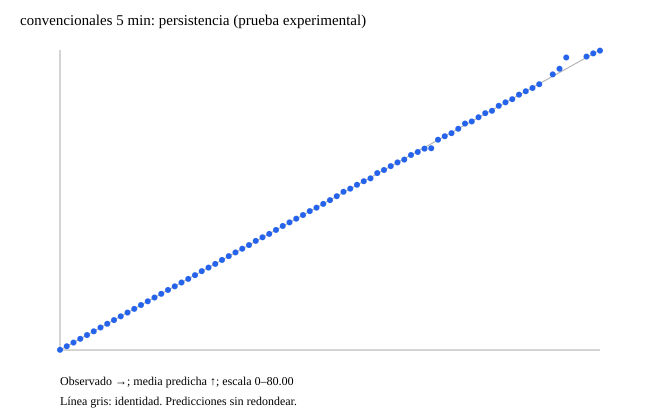

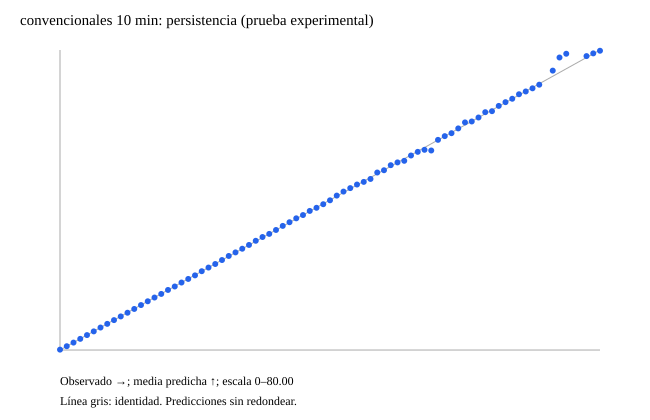

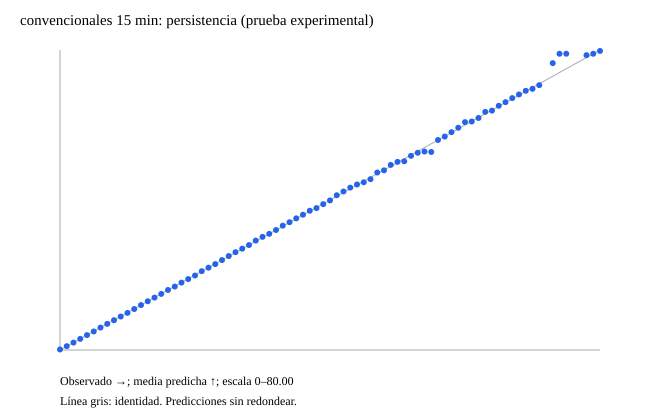

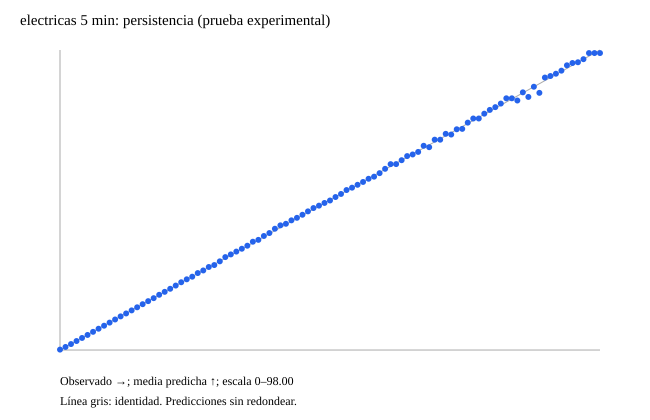

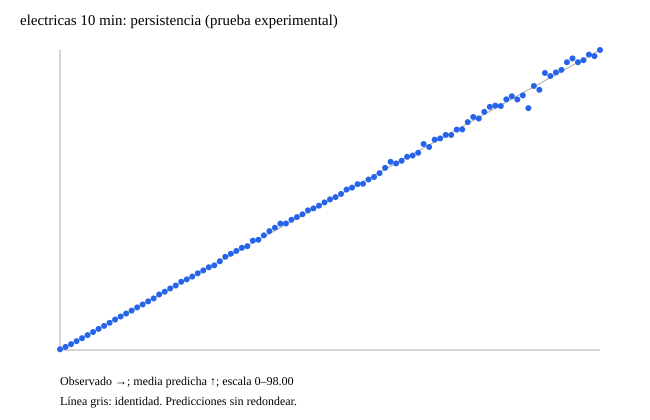

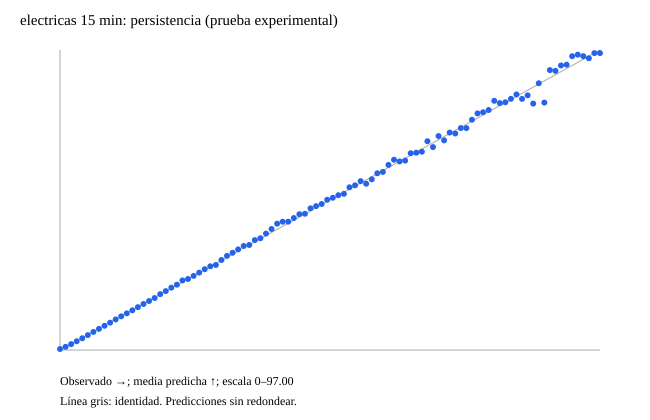

In [3]:
prueba = spark.read.parquet(str(GOLD/'aceptados')).where(F.col('particion_temporal')=='prueba')
prueba_resultados = evaluar_prueba(prueba,estudio,DESTINO_MODELOS)
assert estudio['frozen']['congelada_utc'] < prueba_resultados['lectura_prueba_utc']
print(json.dumps(prueba_resultados,default=str,ensure_ascii=False,indent=2))
for seleccion in estudio['frozen']['selecciones']:
    key = f"{seleccion['tipo']}_{seleccion['h']}min"
    display(SVG(filename=str(DESTINO_MODELOS/(key+'_observado.svg'))))


## Artefactos, recarga y conclusiones

Los modelos seleccionados y sus transformaciones se guardaron antes de prueba. Si gana persistencia, el artefacto es su configuración/contrato: no necesita entrenamiento. Se recarga cada selección y se comparan todas sus predicciones de prueba, tolerancia 1e-10. La evaluación nunca reemplaza al ganador elegido por validación.

Se guardan comparativas completas, métricas por estrato/cambio y estación, predicciones seleccionadas, configuración, medianas train, orden del vector, parámetros, versiones, duración y huellas de Gold. Ningún dato de entrada se modifica.

In [4]:
resultado_modelado = {'version':VERSION,'ejecucion':run_modelado,'destino':str(DESTINO_MODELOS),
    'proveniencia':proveniencia,'seleccion':estudio['frozen'],'sha256_congelacion':estudio['freeze_sha256'],
    'evaluacion':prueba_resultados,'duracion_total_s':perf_counter()-inicio_experimento,
    'nota':'Resultados experimentales de un único día inspeccionado; conteos reportados, exactitud física no confirmada'}
for filename,rows in (('comparacion_validacion.csv',estudio['frozen']['comparativa_validacion']),
                      ('comparacion_prueba.csv',prueba_resultados['metricas_prueba']),
                      ('subgrupos_prueba.csv',prueba_resultados['subgrupos_prueba'])):
    keys=list(dict.fromkeys(k for row in rows for k in row))
    with (DESTINO_MODELOS/filename).open('w',newline='',encoding='utf-8') as stream:
        writer=csv.DictWriter(stream,fieldnames=keys);writer.writeheader();writer.writerows(rows)
guardar_json(DESTINO_MODELOS/'resultado.json',resultado_modelado)
guardar_json(REPORTES_MODELOS/'resultado.json',resultado_modelado)
# Inmutabilidad de los archivos Gold usados y de la selección congelada.
for f in entradas_gold:
    assert hashlib.sha256(Path(f['ruta']).read_bytes()).hexdigest()==f['sha256']
assert hashlib.sha256((DESTINO_MODELOS/'seleccion_congelada.json').read_bytes()).hexdigest()==estudio['freeze_sha256']
guardar_json(REPORTES_MODELOS/'en_curso.json',{'destino':str(DESTINO_MODELOS),'estado':'completo'})
import shutil
for image in DESTINO_MODELOS.glob('*_observado.svg'):
    shutil.copyfile(image,REPORTES_MODELOS/image.name)
print('Duración total (s):',resultado_modelado['duracion_total_s'])
print('Artefactos y tablas:',DESTINO_MODELOS)
spark.stop()


Duración total (s): 270.20227566700123
Artefactos y tablas: /opt/UNIDAD1/Dim-Disponibilidad/data/modelos/20261117T052627988920Z


## Alcance de los resultados

El informe `reports/modelado/hallazgos.md` resume la ejecución. No se extrapolan resultados a otros días ni se elige horizonte usando prueba. Todas las observaciones proceden del único día previamente inspeccionado. La partición llamada prueba no constituye una evaluación final independiente y los errores se miden frente a reportes, no contra inventario físico verificado. No se implementa U2 ni la integración final.

# Fase 6 — integración reproducible de U1

Sección independiente: ejecutar después de completar el punto de entrada desde el host:

```bash
.venv/bin/python pyspark/jupyter/UNIDAD1/Dim-Disponibilidad/ejecutar_u1.py --nueva
```

El flujo completo de lectura → Silver → Gold → comparación → selección → prueba → recarga
se ejecuta en el Docker existente. El comando sin `--nueva` reutiliza únicamente resultados
compatibles y vuelve a verificar artefactos. Esta sección muestra el manifiesto de una
**ejecución integrada nueva y completada** y verifica otra vez sus selecciones guardadas.
No ejecuta las celdas históricas previas ni descarga datos. No implementa U2.


In [1]:
from pathlib import Path
import json, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/flujo_u1.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from pyspark.sql import SparkSession
from src.ejecucion import comprobar_artefactos, inventario, codigo
from src.flujo_u1 import recargar_y_verificar
spark = (SparkSession.builder.master('local[2]').appName('Disponibilidad-U1-verificacion')
         .config('spark.sql.session.timeZone','UTC').config('spark.sql.shuffle.partitions',8)
         .config('spark.ui.enabled','false').getOrCreate())
spark.sparkContext.setLogLevel('WARN')
candidates = []
for path in sorted((ROOT/'data/ejecuciones').glob('*/manifiesto.json')):
    obj = json.loads(path.read_text())
    if obj.get('estado')=='completada' and obj.get('modo')=='nueva':
        candidates.append((path,obj))
if not candidates:
    raise RuntimeError('Primero ejecutar el flujo integrado desde el host; no se toman Gold/modelos históricos por separado')
manifest_path, manifest = candidates[-1]
run = manifest_path.parent
assert codigo()==manifest['codigo_sha256'], 'El código cambió: ejecutar de nuevo el flujo integrado'
assert inventario(ROOT/'data/raw',manifest['configuracion'])==manifest['entradas']
comprobar_artefactos(run,manifest['artefactos'])
print('Ejecución:',manifest['id'], 'modo:',manifest['modo'], 'estado:',manifest['estado'])
print('Versiones:',manifest['versiones'])
print('Linaje:',manifest['linaje'])
print('Periodo y cortes:',manifest['configuracion'])
print('Duración (s):',manifest['duracion_s'])


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/17 14:57:20 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Ejecución: 20261117T142303450900Z modo: nueva estado: completada
Versiones: {'integracion': 'u1-integrado-v1', 'silver': 'silver-v2-tipos-gbfs', 'gold': 'gold-v1-conteos-reportados', 'modelado': 'modelado-v1-validacion-mae', 'spark': '4.2.0', 'python': '3.10.22', 'java': '21.0.13', 'docker_imagen_id': 'sha256:776b7bfde33a05e845392e5bf9cc88be81167c0b328f40142de729def297120d'}
Linaje: {'raw': 'data/raw', 'silver': '/opt/UNIDAD1/Dim-Disponibilidad/data/ejecuciones/20261117T142303450900Z/silver', 'gold': '/opt/UNIDAD1/Dim-Disponibilidad/data/ejecuciones/20261117T142303450900Z/gold', 'modelos': '/opt/UNIDAD1/Dim-Disponibilidad/data/ejecuciones/20261117T142303450900Z/modelos', 'silver_ejecucion': '20261117T142303450900Z', 'gold_ejecucion': '20261117T142303450900Z', 'modelos_ejecucion': '20261117T142303450900Z'}
Periodo y cortes: {'desde': '2026-11-10', 'hasta': '2026-11-10', 'corte_validacion_utc': '2026-11-10 16:00:00', 'corte_prueba_utc': '2026-11-10 20:00:00', 'fin_exclusivo_utc': '2026-1

In [2]:
print('Fuentes:', manifest['fuentes'])
print('Silver/Gold:', {k:v for k,v in manifest['conteos'].items() if k!='por_tipo_horizonte_particion'})
spark.createDataFrame(manifest['conteos']['por_tipo_horizonte_particion']).orderBy('tipo','horizonte_min','particion_temporal').show(30,truncate=False)
cols = ['tipo','horizonte_min','candidato','n','MAE','RMSE','R2']
spark.createDataFrame([{k:r[k] for k in cols} for r in manifest['metricas']]).orderBy('tipo','horizonte_min').show(truncate=False)
print('Ajustes MLlib realizados:',manifest['ajustes_mllib'])
print('Selecciones (persistencia no necesita entrenamiento):',manifest['selecciones'])


Fuentes: [{'fuente': 'station_status', 'archivos': 288, 'registros': 725706}, {'fuente': 'station_information', 'archivos': 1, 'registros': 2520}, {'fuente': 'vehicle_types', 'archivos': 1, 'registros': 2}]
Silver/Gold: {'silver': {'entrada': 725706, 'aceptados': 707762, 'excluidos': 17944, 'schema_verificado': True, 'multiconjunto_reconciliado': True}, 'gold': {'candidatos': 2177118, 'aceptados': 2078519, 'excluidos': 98599}}


+------+-------------+------------------+--------------+
|count |horizonte_min|particion_temporal|tipo          |
+------+-------------+------------------+--------------+
|115361|5            |prueba            |convencionales|
|469669|5            |train             |convencionales|
|115267|5            |validacion        |convencionales|
|112896|10           |prueba            |convencionales|
|467147|10           |train             |convencionales|
|112792|10           |validacion        |convencionales|
|110431|15           |prueba            |convencionales|
|464635|15           |train             |convencionales|
|110321|15           |validacion        |convencionales|
|115361|5            |prueba            |electricas    |
|469669|5            |train             |electricas    |
|115267|5            |validacion        |electricas    |
|112896|10           |prueba            |electricas    |
|467147|10           |train             |electricas    |
|112792|10           |validacio

+-------------------+------------------+------------------+------------+-------------+------+--------------+
|MAE                |R2                |RMSE              |candidato   |horizonte_min|n     |tipo          |
+-------------------+------------------+------------------+------------+-------------+------+--------------+
|0.17799776354227165|0.996867683856441 |0.5051893053657652|persistencia|5            |115361|convencionales|
|0.30440405328798187|0.9934973881725175|0.727506613726551 |persistencia|10           |112896|convencionales|
|0.40746710615678566|0.9899494914257374|0.9039450041502542|persistencia|15           |110431|convencionales|
|0.3968498886105356 |0.9906795028101671|0.8857704250720579|persistencia|5            |115361|electricas    |
|0.635859552154195  |0.9799554860903451|1.294447850666545 |persistencia|10           |112896|electricas    |
|0.82618105423296   |0.9680112800785837|1.6293328620162553|persistencia|15           |110431|electricas    |
+------------------

In [3]:
proofs = recargar_y_verificar(spark,run,manifest)
comprobar_artefactos(run,manifest['artefactos'])
for proof in proofs:
    print(proof)
assert len(proofs)==6 and all(p['max_diferencia']<=1e-10 and p['nulos']==0 for p in proofs)
print('Se reproducen todas las predicciones seleccionadas y los conteos/MAE por estación.')
spark.stop()


{'tipo': 'convencionales', 'horizonte_min': 5, 'n': 115361, 'nulos': 0, 'max_diferencia': 0.0, 'MAE_reproducido': 0.17799776354227165}
{'tipo': 'convencionales', 'horizonte_min': 10, 'n': 112896, 'nulos': 0, 'max_diferencia': 0.0, 'MAE_reproducido': 0.30440405328798187}
{'tipo': 'convencionales', 'horizonte_min': 15, 'n': 110431, 'nulos': 0, 'max_diferencia': 0.0, 'MAE_reproducido': 0.40746710615678566}
{'tipo': 'electricas', 'horizonte_min': 5, 'n': 115361, 'nulos': 0, 'max_diferencia': 0.0, 'MAE_reproducido': 0.3968498886105356}
{'tipo': 'electricas', 'horizonte_min': 10, 'n': 112896, 'nulos': 0, 'max_diferencia': 0.0, 'MAE_reproducido': 0.635859552154195}
{'tipo': 'electricas', 'horizonte_min': 15, 'n': 110431, 'nulos': 0, 'max_diferencia': 0.0, 'MAE_reproducido': 0.82618105423296}
Se reproducen todas las predicciones seleccionadas y los conteos/MAE por estación.


## Interpretación de la entrega

Los candidatos LR y RF se entrenaron y evaluaron; los seis ganadores actuales son
contratos de persistencia, sin entrenamiento. Los objetivos son conteos reportados
por tipo, cuya exactitud física no está confirmada. Las discrepancias iniciales y
futuras se conservan; las futuras nunca son predictores. El informe de fase 5 muestra
la comparación completa y el error condicionado a cambios y discrepancias.

Los resultados son experimentales: un único día UTC ya inspeccionado, cortes por
horarios distintos, sin prueba final independiente ni evidencia de generalización
semanal o estacional. U2 y el capturador externo no se acreditan como implementados.
La rúbrica oficial vigente no aparece en la rama: su contraste permanece pendiente;
la matriz documental provisional y los comandos de ampliación están en
`reports/integracion/entrega_u1.md` y la ejecución comprobada en `verificacion.md`.
